# COPE Score Analysis

Building analysis: how completely are the COPE attributes documented for each building in Nepal?

## 1. Setup and Paths

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

load_dotenv()

#Plot style (consistent across all notebooks of the thesis)
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})

In [ ]:
#Get buildings from DB

db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST", "localhost")
db_port = os.getenv("DB_PORT", "5432")
db_name = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}"
)

buildings = gpd.read_postgis(
    "SELECT * FROM buildings_points", engine, geom_col="geom"
)

buildings_df = pd.DataFrame(buildings)

buildings.shape

(8257300, 70)

## 2. Attribute Overview

In [3]:
# Regular columns
normal_columns = [c for c in buildings.columns if c != "geom"]

# Keys inside the hstore column 'tags' (determined server-side via skeys())
tag_keys = pd.read_sql(
    "SELECT DISTINCT skeys(tags) AS key FROM buildings_points ORDER BY key",
    engine,
)["key"].tolist()

all_attributes = normal_columns + tag_keys

print(f"{len(normal_columns)} regular columns:")
for col in normal_columns:
    print(" -", col)

print(f"\n{len(tag_keys)} additional attributes in 'tags' (hstore):")
for key in tag_keys:
    print(" -", key)

print(f"\nTotal: {len(all_attributes)} attributes")

69 regular columns:
 - osm_id
 - access
 - addr:housename
 - addr:housenumber
 - addr:interpolation
 - admin_level
 - aerialway
 - aeroway
 - amenity
 - area
 - barrier
 - bicycle
 - brand
 - bridge
 - boundary
 - building
 - construction
 - covered
 - culvert
 - cutting
 - denomination
 - disused
 - embankment
 - foot
 - generator:source
 - harbour
 - highway
 - historic
 - horse
 - intermittent
 - junction
 - landuse
 - layer
 - leisure
 - lock
 - man_made
 - military
 - motorcar
 - name
 - natural
 - office
 - oneway
 - operator
 - place
 - population
 - power
 - power_source
 - public_transport
 - railway
 - ref
 - religion
 - route
 - service
 - shop
 - sport
 - surface
 - toll
 - tourism
 - tower:type
 - tracktype
 - tunnel
 - water
 - waterway
 - wetland
 - width
 - wood
 - z_order
 - way_area
 - tags

728 additional attributes in 'tags' (hstore):
 - 4wd_only
 - abandoned
 - abandoned:amenity
 - addr:
 - addr:bardiya
 - addr:city
 - addr:country
 - addr:district
 - addr:full
 - 

### Inspect the values of a single attribute

In [8]:
# Inspect different keys to understand more about their data and purpose.
# This section is for normal keys

column_name = "amenity"  # <- enter a column name

buildings_df[column_name].value_counts(dropna=False)

amenity
NaN                             8252524
place_of_worship                   1359
restaurant                          608
school                              570
toilets                             231
                                 ...   
gym, fitness centre, private          1
car_decoration                        1
language_school                       1
janjoti adarvut school                1
gov office                            1
Name: count, Length: 143, dtype: int64

In [9]:
# Inspect different keys to understand more about their data and purpose.
# This section is for keys inside the hstore column 'tags'

tag_key = "building:adjacency"  # <- enter a key from tag_keys here

pd.read_sql(
    text(
        "SELECT tags -> :key AS value, COUNT(*) AS n "
        "FROM buildings_points GROUP BY value ORDER BY n DESC"
    ),
    engine,
    params={"key": tag_key},
)

,value,n
0,NaN,8236125
1,free_standing,4646
2,no,4097
3,detached,3995
4,one_side,2598
5,two_side,1501
6,yes,1401
7,attached,1250
8,one_side_different_height,979
9,one_side_same_height,283


## 3. COPE Score Schema

Here, we define which keys belong to which COPE subcategory

Special cases:
- `e_address`: more complex AND/OR logic (see `ADDRESS_SCHEMA`)
- `p_sprinkler`: no keys
- `building`: only counts if it is set **and** not equal to `"yes"`
- The location (`e_location` in the PDF) is **not** scored. Every building has a geometry, so this point would be identical for all buildings and say nothing about attribute completeness.

In [10]:
COPE_SCHEMA = {
    "C": {  # CONSTRUCTION - 10 points
        "c_shape": ["shape:elevation", "shape:plan"],
        "c_age": ["start_date", "building:age", "construction_date"],
        "c_physical_condition": [
            "physical_condition", "physical:condition", "damage:event", "condition",
            "damage", "damage:type", "damaged", "damaged:building", "earthquake:damage",
            "building:condition", "building:damage_grade_Gorkha_eq",
        ],
        "c_height": ["building:levels", "height", "level", "levels", "building:level"],
        "c_structure_geometry": [
            "building:irregularity", "building:irregularity:type", "building:overhang",
        ],
        "c_structure_material": [
            "building:structure", "building:material", "wall", "brick:material", "brick_kind",
            "material", "structure", "wall:material", "wall:thickness", "building:gable_wall",
            "building:lateral:material", "building:lateral:system", "building:type_of_construction",
        ],
        "c_roof_material": [
            "roof:material", "roof:condition", "roof:cover:material", "roof:material:type", "roof:surface",
        ],
        "c_roof_shape": [
            "roof:shape", "roof", "roof:levels", "roof:height", "roof:type", "building:roof_type",
        ],
        "c_interior_construction": [
            "building:bay:x", "building:bay:y", "building:soft_storey", "floor:material", "floor",
            "floor:material:type", "building:floor", "building:floor_type",
        ],
        "c_size": ["building:approx_footprint_area", "building:area"],
    },
    "O": {  # OCCUPANCY - 4 points
        "o_use": [
            "amenity", "building", "construction", "building:primary_occupancy",
            "building:use", "building:type",
        ],
        "o_floors": ["building:levels", "level", "levels", "building:level"],
        "o_occupants_day": [
            "occupant:day", "occupant:morning", "population", "abandoned", "child:count",
            "count:personal", "family:count", "number_of_students", "personal:count",
            "personnel:count", "population:count", "opd:patients:count", "student:count",
            "building:occupant_num",
        ],
        "o_occupants_night": [
            "occupant:evening", "occupant:night", "population", "abandoned",
            "population:count", "opd:patients:count", "building:occupant_num",
        ],
    },
    "P": {  # PROTECTION - 6 points
        "p_sprinkler": [],  # no source in the PDF -> always 0
        "p_equipment": ["rescue_kit_pre_position"],
        "p_reinforcements": ["retrofit", "shelter_type", "safe_place", "shelter", "building:typology"],
        "p_seismic_resistance": ["seismic_resistance", "post-quake build", "post-quake-build"],
        "p_capacity": [
            "capacity:beds", "beds", "capacity", "capacity:bed", "capacity:persons",
            "Household code", "Household Code", "household_code", "Household_code", "Household_Code",
            "number_of_classrooms", "building:rooms",
        ],
        "p_wheelchair": ["wheelchair"],
    },
    "E": {  # EXPOSURE - 4 points (e_address handled separately, see ADDRESS_SCHEMA)
        "e_damage": [
            "damage:event", "condition", "damage", "damage:type", "damaged", "damaged:building",
            "earthquake:damage", "building:condition", "building:damage_grade_Gorkha_eq",
        ],
        "e_adjacent": ["building:adjacency", "building:adjacency:difference", "building:adjacency:level"],
        "e_hazard_zone": [
            "affected:hazard", "awareness:red_cross", "disaster_risk:flood", "flood_prone",
            "flood_Risk", "hazard_risk:flood", "natural_hazard", "risk",
            "building:geological_site", "building:groundslope",
        ],
    },
}

# e_address: addr:full OR address OR (house number group AND street group AND place group)
ADDRESS_SCHEMA = {
    "standalone": ["addr:full", "address"],
    "housenumber": ["addr:housenumber", "building:number"],
    "street": ["addr:street", "addr:street:ne", "street"],
    "place": [
        "addr:city", "addr:district", "addr:hamlet", "addr:municipality", "addr:place",
        "addr:postcode", "addr:subdistrict", "addr:suburb", "addr:tole", "addr:village",
        "addr:ward", "addr:ward_number", "city", "District", "district",
    ],
}

E_SUBCATS_ORDER = ["e_address", "e_damage", "e_adjacent", "e_hazard_zone"]

# Attributes for which NULL alone is not enough -- these values also count as "not set"
ATTR_VALUE_EXCLUSIONS = {
    "building": ["yes"],  # building=yes is the OSM default/placeholder value, not real information
}

## 4. Compute the COPE Score (in Postgres)

In [ ]:
def attr_expr(name, normal_columns_set):
    """SQL expression: is this attribute meaningfully set?"""
    ref = f'"{name}"' if name in normal_columns_set else f"(tags -> '{name}')"
    expr = f"{ref} IS NOT NULL"
    for excluded_value in ATTR_VALUE_EXCLUSIONS.get(name, []):
        expr += f" AND {ref} <> '{excluded_value}'"
    return expr


def subcat_expr(attrs, normal_columns_set):
    if not attrs:
        return "FALSE"
    return "(" + " OR ".join(attr_expr(a, normal_columns_set) for a in attrs) + ")"


def build_cope_sql(table="buildings_points", normal_columns_set=None):
    if normal_columns_set is None:
        normal_columns_set = set()

    # --- inner SELECT: one boolean per sub-category ---
    inner_cols = ["osm_id", "geom"]
    for cat in ("C", "O", "P"):
        for subcat, attrs in COPE_SCHEMA[cat].items():
            inner_cols.append(f"{subcat_expr(attrs, normal_columns_set)} AS {subcat}")

    standalone = subcat_expr(ADDRESS_SCHEMA["standalone"], normal_columns_set)
    housenumber = subcat_expr(ADDRESS_SCHEMA["housenumber"], normal_columns_set)
    street = subcat_expr(ADDRESS_SCHEMA["street"], normal_columns_set)
    place = subcat_expr(ADDRESS_SCHEMA["place"], normal_columns_set)
    e_address_expr = f"({standalone} OR ({housenumber} AND {street} AND {place}))"
    inner_cols.append(f"{e_address_expr} AS e_address")

    for subcat in ("e_damage", "e_adjacent", "e_hazard_zone"):
        inner_cols.append(f"{subcat_expr(COPE_SCHEMA['E'][subcat], normal_columns_set)} AS {subcat}")

    inner_sql = "SELECT\n    " + ",\n    ".join(inner_cols) + f"\nFROM {table}"

    # --- outer SELECT: sub-category + dimension sums + total score ---
    c_subcats = list(COPE_SCHEMA["C"].keys())
    o_subcats = list(COPE_SCHEMA["O"].keys())
    p_subcats = list(COPE_SCHEMA["P"].keys())
    e_subcats = E_SUBCATS_ORDER
    all_subcats = c_subcats + o_subcats + p_subcats + e_subcats

    outer_cols = ["osm_id", "geom"] + all_subcats
    outer_cols.append("(" + " + ".join(f"{s}::int" for s in c_subcats) + ') AS "C"')
    outer_cols.append("(" + " + ".join(f"{s}::int" for s in o_subcats) + ') AS "O"')
    outer_cols.append("(" + " + ".join(f"{s}::int" for s in p_subcats) + ') AS "P"')
    outer_cols.append("(" + " + ".join(f"{s}::int" for s in e_subcats) + ') AS "E"')
    outer_cols.append("(" + " + ".join(f"{s}::int" for s in all_subcats) + ") AS cope_score")

    return "SELECT\n    " + ",\n    ".join(outer_cols) + f"\nFROM (\n{inner_sql}\n) sub"


cope_sql = build_cope_sql(normal_columns_set=set(normal_columns))

with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS cope_scores"))
    conn.execute(text(f"CREATE TABLE cope_scores AS\n{cope_sql}"))
    conn.execute(text("CREATE INDEX idx_cope_scores_osm_id ON cope_scores (osm_id)"))
    conn.execute(text("CREATE INDEX idx_cope_scores_geom ON cope_scores USING GIST (geom)"))

print("Table 'cope_scores' created.")

Table 'cope_scores' created.


## 5. Distribution per COPE Dimension

The four dimensions are analysed **separately**, not as a total score.

The plot shows the log of the values due to the imense differences.

Buildings in total: 8,257,300

                  max_points   mean  completeness_pct  max_observed
category                                                           
C (Construction)          10  0.024             0.244           9.0
O (Occupancy)              4  0.033             0.817           4.0
P (Protection)             6  0.002             0.032           4.0
E (Exposure)               4  0.005             0.121           3.0

Share of buildings per score (%):
              C        O        P        E
points                                    
0       99.3719  97.1871  99.8725  99.6728
1        0.2323   2.4809   0.0666   0.1991
2        0.1181   0.2635   0.0588   0.0988
3        0.0096   0.0153   0.0020   0.0293
4        0.0026   0.0532   0.0000   0.0000
5        0.0094   0.0000   0.0000   0.0000
6        0.0944   0.0000   0.0000   0.0000
7        0.0386   0.0000   0.0000   0.0000
8        0.0564   0.0000   0.0000   0.0000
9        0.0669   0.0000   0.0000   0.0000


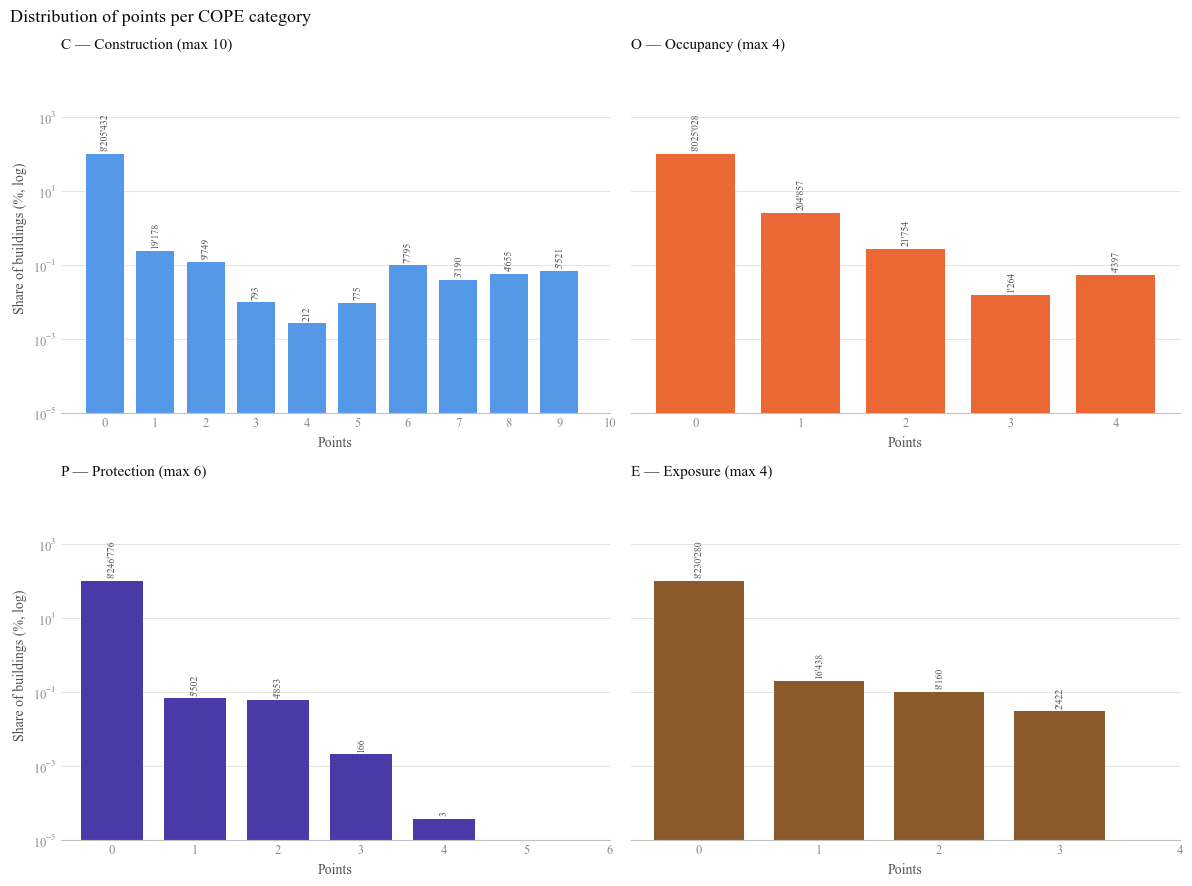

In [11]:
import numpy as np

CATEGORIES = {
    "C": {"name": "Construction", "max_points": 10},
    "O": {"name": "Occupancy", "max_points": 4},
    "P": {"name": "Protection", "max_points": 6},
    "E": {"name": "Exposure", "max_points": 4},
}


def completeness(mean, cat):
    """Attribute completeness: mean points relative to the maximum attainable points of the category (%)."""
    return 100 * mean / CATEGORIES[cat]["max_points"]


SUBCATS = {cat: (E_SUBCATS_ORDER if cat == "E" else list(COPE_SCHEMA[cat])) for cat in CATEGORIES}
ALL_SUBCATS = [s for subs in SUBCATS.values() for s in subs]
CATEGORY_OF = {s: cat for cat, subs in SUBCATS.items() for s in subs}

# Colours and text colours (consistent across all figures in this notebook)
CAT_COLORS = {"C": "#5598e7", "O": "#eb6834", "P": "#4a3aa7", "E": "#8a5a2b"}
INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"


def style_axes(ax, x_grid=True):
    ax.grid(axis="x" if x_grid else "y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")


# Frequency of each score combination - every dimension can be analysed separately from it
cat_counts = pd.read_sql('SELECT "C", "O", "P", "E", COUNT(*) AS n FROM cope_scores GROUP BY 1, 2, 3, 4', engine)
n_buildings_total = int(cat_counts["n"].sum())
print(f"Buildings in total: {n_buildings_total:,}\n")

rows, dist = [], {}
for cat, info in CATEGORIES.items():
    points = cat_counts.groupby(cat)["n"].sum().sort_index()
    v, w = points.index.to_numpy(float), points.to_numpy(float)
    dist[cat] = 100 * points / n_buildings_total
    rows.append({
        "category": f"{cat} ({info['name']})",
        "max_points": info["max_points"],
        "mean": (v * w).sum() / w.sum(),
        "completeness_pct": completeness((v * w).sum() / w.sum(), cat),
        "max_observed": v.max()
    })

stats_cat = pd.DataFrame(rows).set_index("category")
print(stats_cat.round(3).to_string())

print("\nShare of buildings per score (%):")
print(pd.DataFrame(dist).fillna(0).rename_axis("points").round(4).to_string())

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for ax, (cat, info) in zip(axes.flat, CATEGORIES.items()):
    points = cat_counts.groupby(cat)["n"].sum().sort_index()
    shares = 100 * points / n_buildings_total
    ax.bar(points.index, shares, color=CAT_COLORS[cat], width=0.75)
    # absolute number of buildings above each bar (the shares are on the axis)
    for x, share, n in zip(points.index, shares, points):
        ax.text(x, share * 1.25, f"{n:,}".replace(",", "'"), ha="center", va="bottom",
                fontsize=7, rotation=90, color=INK_SECONDARY)
    ax.set_yscale("log")
    # lower limit low enough that even the smallest bar (a single building) stays visible,
    # room at the top for the vertical labels
    ax.set_ylim(1e-5, 30_000)
    ax.set_xticks(range(0, info["max_points"] + 1))
    ax.set_xlabel("Points", color=INK_SECONDARY, fontsize=10)
    ax.set_title(f"{cat} — {info['name']} (max {info['max_points']})", loc="left", fontsize=11,
                 color=INK, pad=10)
    style_axes(ax, x_grid=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Share of buildings (%, log)", color=INK_SECONDARY, fontsize=10)
fig.suptitle("Distribution of points per COPE category", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()

## 6. Ranking of the Subcategories

This section shows which COPE subcategories occur the most and which are practically missing. `p_sprinkler` (never fulfilled) is listed only for completeness.

 rank           sub_indicator category  n_buildings  share_pct
    1                   o_use        O       222996     2.7006
    2                c_height        C        35689     0.4322
    3                o_floors        O        35294     0.4274
    4         c_roof_material        C        31847     0.3857
    5    c_structure_material        C        28304     0.3428
    6            c_roof_shape        C        26068     0.3157
    7              e_adjacent        E        21175     0.2564
    8    c_structure_geometry        C        18868     0.2285
    9                 c_shape        C        18856     0.2284
   10    c_physical_condition        C        16861     0.2042
   11 c_interior_construction        C        15564     0.1885
   12           e_hazard_zone        E        12969     0.1571
   13                   c_age        C         9029     0.1093
   14         o_occupants_day        O         6456     0.0782
   15        p_reinforcements        P         5241    

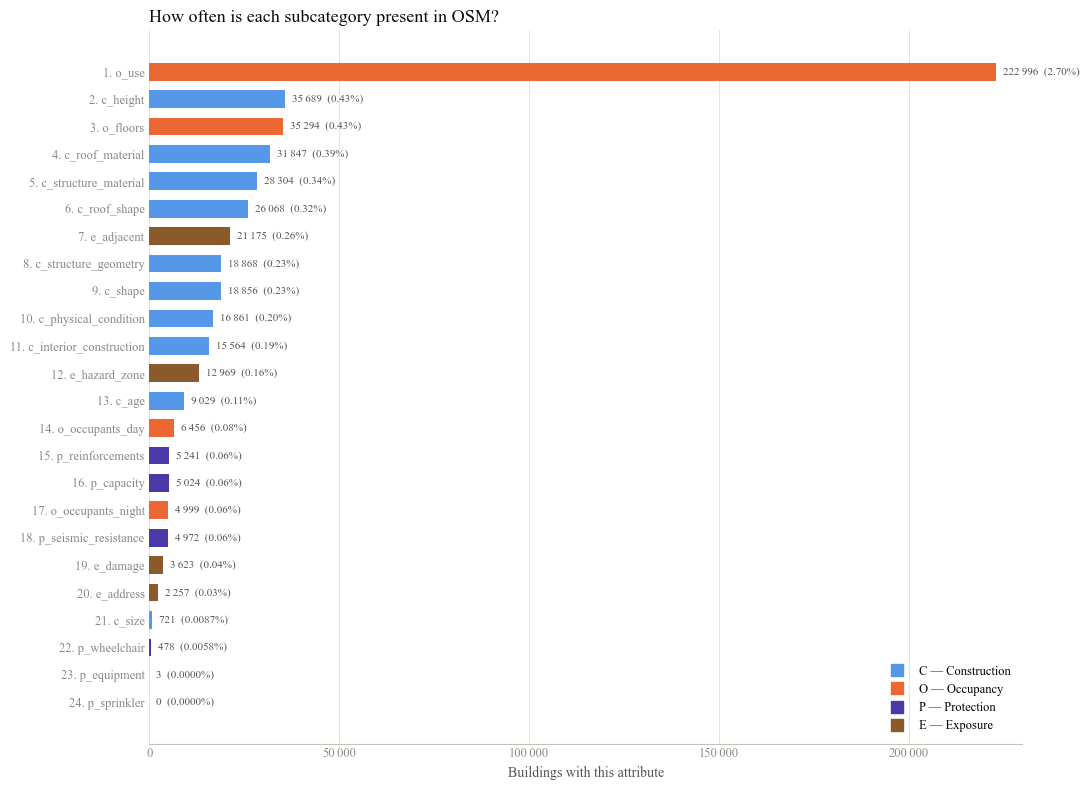

In [10]:
sub_sql = ", ".join(f"SUM({s}::int) AS {s}" for s in ALL_SUBCATS)
sub_totals = pd.read_sql(text(f"SELECT {sub_sql} FROM cope_scores"), engine).iloc[0]

ranking = pd.DataFrame({
    "sub_indicator": ALL_SUBCATS,
    "category": [CATEGORY_OF[s] for s in ALL_SUBCATS],
    "n_buildings": [int(sub_totals[s]) for s in ALL_SUBCATS],
})
ranking["share_pct"] = 100 * ranking["n_buildings"] / n_buildings_total
ranking = ranking.sort_values("n_buildings", ascending=False).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
print(ranking.round(4).to_string(index=False))

def thousands(n):
    return f"{int(n):,}".replace(",", "\u2009")   # thin space as thousands separator


def ranking_plot(x_max):
    """Ranking with a linear x-axis. Bars beyond x_max end with an arrow at the edge,
    their true value is written inside the bar."""
    fig, ax = plt.subplots(figsize=(11, 8))
    y = np.arange(len(ranking))[::-1]
    values = ranking["n_buildings"].to_numpy()
    clipped = values > x_max

    ax.barh(y, np.minimum(values, x_max), height=0.65,
            color=[CAT_COLORS[c] for c in ranking["category"]])
    if clipped.any():
        ax.plot([x_max] * clipped.sum(), y[clipped], ">", color=INK_SECONDARY,
                markersize=7, clip_on=False)

    for yi, n, pct, is_clipped in zip(y, values, ranking["share_pct"], clipped):
        share = f"{pct:.2f}%" if pct >= 0.01 else f"{pct:.4f}%"
        if is_clipped:   # bar is cut off -> value in white inside the bar
            ax.text(x_max * 0.98, yi, f"{thousands(n)}  ({share})", ha="right", va="center",
                    fontsize=8, color="white")
        else:
            ax.text(n + x_max * 0.008, yi, f"{thousands(n)}  ({share})", va="center",
                    fontsize=8, color=INK_SECONDARY)

    ax.set_yticks(y, [f"{r}. {s}" for r, s in zip(ranking["rank"], ranking["sub_indicator"])],
                  fontsize=9, color=INK)
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(lambda v, pos: thousands(v))
    ax.set_xlabel("Buildings with this attribute", color=INK_SECONDARY, fontsize=10)
    ax.legend(handles=[plt.Line2D([], [], ls="", marker="s", markersize=8, color=CAT_COLORS[c],
                                  label=f"{c} — {CATEGORIES[c]['name']}") for c in CATEGORIES],
              loc="lower right", frameon=False, fontsize=9)
    ax.set_title("How often is each subcategory present in OSM?",
                 loc="left", fontsize=13, color=INK)
    style_axes(ax)
    fig.tight_layout()
    plt.show()


# x-axis up to 230,000 so that o_use, the most frequent sub-indicator, fits into the figure
ranking_plot(230_000)

## 7. Spatial Distribution: COPE Completeness per Municipality

The completeness is evaluated **per municipality**..

Each building is assigned to the municipality its point lies in (`ST_Within`, unique). Per municipality we then sum up: points per dimension, number of buildings and number of buildings with at least one attribute.

**Metrics per municipality and category:**

- `mean_C` … `mean_E`: mean points per building
- `compl_C_pct` … `compl_E_pct`: attribute completeness (mean points relative to the dimension maximum)
- `share_C_pct` … `share_E_pct`: share of buildings with at least one attribute in this dimension

Province, district (with hazard zone) and municipality type are added via the representative point of the municipality, as in the coverage notebooks.

In [12]:
data_dir = r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data"
border_dir = f"{data_dir}\\nepal_border_osm_shp"
PROVINCE_NAMES = {"NP-P1": "Koshi", "NP-P2": "Madhesh", "NP-P3": "Bagmati", "NP-P4": "Gandaki",
                  "NP-P5": "Lumbini", "NP-P6": "Karnali", "NP-P7": "Sudurpashchim"}
HAZARD_ZONES = ["very low", "low", "moderate", "high", "very high"]

# --- COPE sums per municipality (spatial join in Postgres) ---
sub_sum_sql = ",\n       ".join(f"SUM(c.{s}::int) AS {s}" for s in ALL_SUBCATS)
cope_muni = pd.read_sql(text(f"""
    SELECT m.osm_id AS osm_id,
           COUNT(*) AS n_buildings,
           SUM(c."C") AS "points_C", SUM(c."O") AS "points_O",
           SUM(c."P") AS "points_P", SUM(c."E") AS "points_E",
           SUM((c."C" > 0)::int) AS "with_C", SUM((c."O" > 0)::int) AS "with_O",
           SUM((c."P" > 0)::int) AS "with_P", SUM((c."E" > 0)::int) AS "with_E",
           {sub_sum_sql}
    FROM cope_scores c
    JOIN nepal_municipalities m ON ST_Within(c.geom, m.way)
    GROUP BY m.osm_id
"""), engine)
print(f"Buildings assigned to a municipality: {int(cope_muni['n_buildings'].sum()):,} of {n_buildings_total:,} "
      f"({100 * cope_muni['n_buildings'].sum() / n_buildings_total:.1f}%)")

# --- municipalities with province, district and hazard zone ---
municipalities = gpd.read_postgis(
    """
    SELECT osm_id, name, tags -> 'name:en' AS name_en, municipality_type, way
    FROM nepal_municipalities
    """,
    engine, geom_col="way",
).rename_geometry("geometry")
municipalities = municipalities.dissolve(by="osm_id", aggfunc="first").reset_index()   # multi-part municipalities
municipalities["municipality"] = municipalities["name_en"].fillna(municipalities["name"])

provinces = gpd.read_file(f"{border_dir}\\nepal_provinces.shp", encoding="latin1")   # tags field is not readable as UTF-8
provinces["province"] = provinces["tags"].str.extract(r"ISO3166-2: (NP-P\d)", expand=False).map(PROVINCE_NAMES)
provinces = provinces[["province", "geometry"]].to_crs(municipalities.crs)

districts = gpd.read_postgis(
    "SELECT COALESCE(tags -> 'name:en', name) AS district, hazard_zone, way FROM nepal_districts",
    engine, geom_col="way",
).rename_geometry("geometry").to_crs(municipalities.crs)

rep = gpd.GeoDataFrame(municipalities[["municipality"]], geometry=municipalities.representative_point(),
                       crs=municipalities.crs)


def assign_by_point(polygons, cols):
    joined = gpd.sjoin(rep, polygons[cols + ["geometry"]], how="left", predicate="within")
    assert not joined.index.duplicated().any(), "point lies in several polygons"
    result = joined[cols].copy()
    missing = result[cols[0]].isna()
    if missing.any():
        near = gpd.sjoin_nearest(rep[missing], polygons[cols + ["geometry"]], how="left")
        result.loc[missing, cols] = near.loc[~near.index.duplicated(), cols]
    return result


municipalities["province"] = assign_by_point(provinces, ["province"])["province"]
municipalities[["district", "hazard_zone"]] = assign_by_point(districts, ["district", "hazard_zone"])

# --- merge and compute the metrics ---
muni = municipalities[["osm_id", "municipality", "municipality_type", "province", "district", "hazard_zone",
                       "geometry"]].merge(cope_muni, on="osm_id", how="left")
count_cols = ["n_buildings"] + [f"points_{c}" for c in CATEGORIES] + [f"with_{c}" for c in CATEGORIES] + ALL_SUBCATS
muni[count_cols] = muni[count_cols].fillna(0).astype(int)

for cat in CATEGORIES:
    n = muni["n_buildings"].where(muni["n_buildings"] > 0)
    muni[f"mean_{cat}"] = muni[f"points_{cat}"] / n
    muni[f"compl_{cat}_pct"] = completeness(muni[f"mean_{cat}"], cat)
    muni[f"share_{cat}_pct"] = 100 * muni[f"with_{cat}"] / n

print(f"Municipalities: {len(muni)} | without buildings: {int((muni['n_buildings'] == 0).sum())}")
print("\nMunicipalities per hazard zone:")
print(muni["hazard_zone"].value_counts().reindex(HAZARD_ZONES).to_string())
print("\nMetrics (example, the 5 municipalities with the most buildings):")
show = ["municipality", "municipality_type", "province", "n_buildings"] + \
       [f"mean_{c}" for c in CATEGORIES] + [f"share_{c}_pct" for c in CATEGORIES]
print(muni.sort_values("n_buildings", ascending=False)[show].head(5).round(3).to_string(index=False))

Buildings assigned to a municipality: 8,079,091 of 8,257,300 (97.8%)
Municipalities: 750 | without buildings: 0

Municipalities per hazard zone:
hazard_zone
very low      13
low          206
moderate     295
high         150
very high     86

Metrics (excerpt, the 5 municipalities with the most buildings):
               municipality     municipality_type province  n_buildings  mean_C  mean_O  mean_P  mean_E  share_C_pct  share_O_pct  share_P_pct  share_E_pct
Kathmandu Metropolitan City     Metropolitan City  Bagmati       148885   0.419   0.180   0.048   0.083        7.270        9.015        3.474        6.142
                    Pokhara     Metropolitan City  Gandaki       140741   0.026   0.035   0.002   0.002        2.033        3.224        0.226        0.206
                  Bharatpur     Metropolitan City  Bagmati       125023   0.497   0.149   0.000   0.130        6.568        8.390        0.001        6.508
                   Tulsipur Sub-Metropolitan City  Lumbini        63

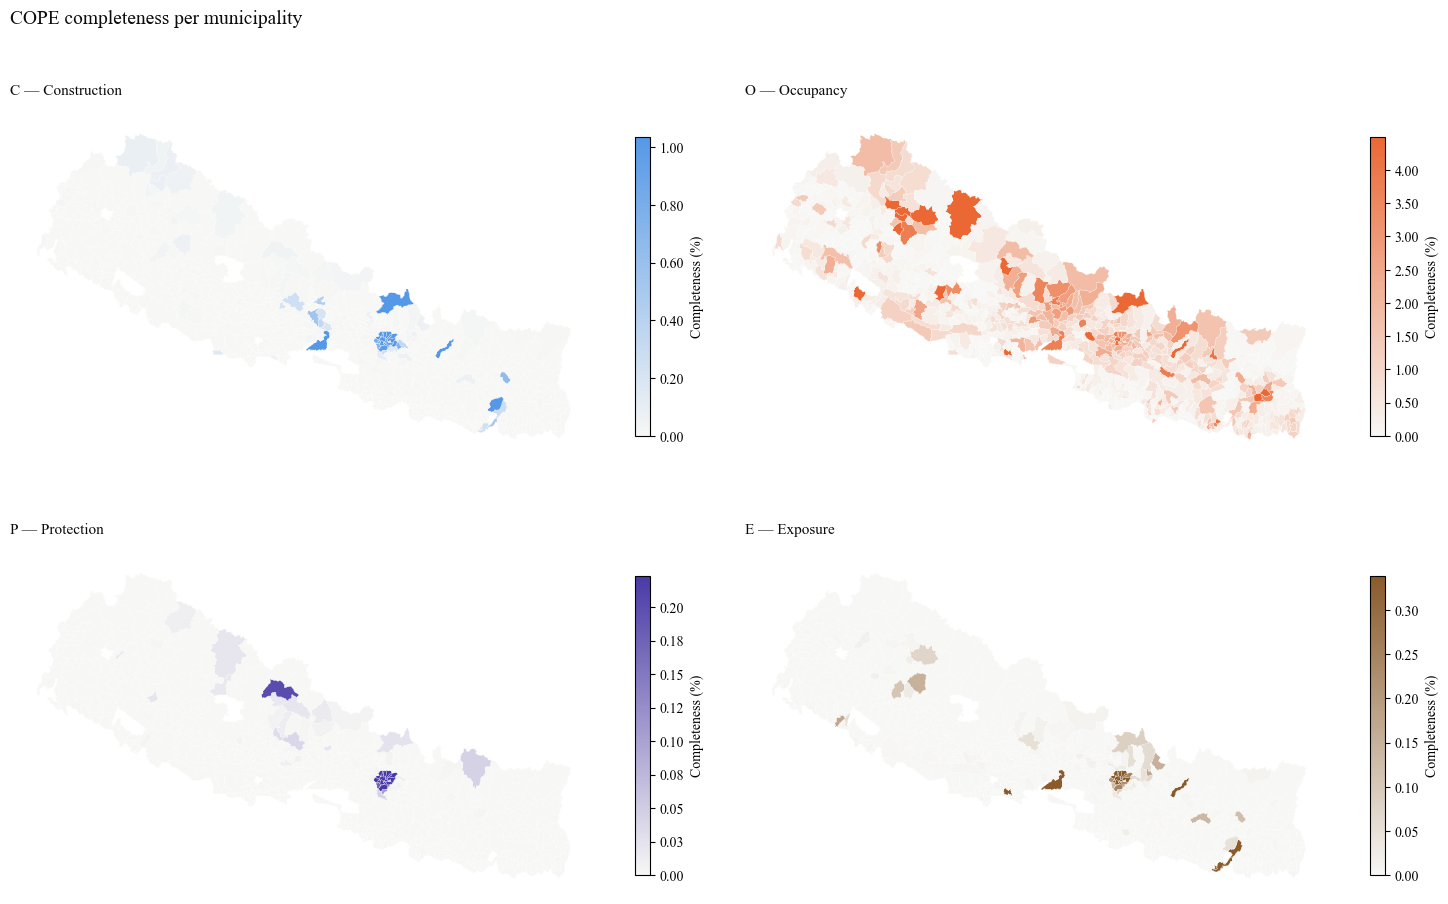

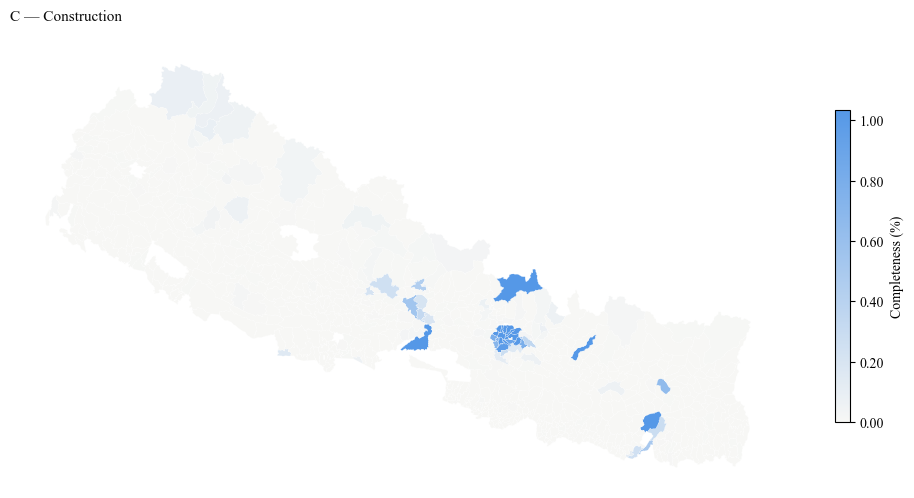

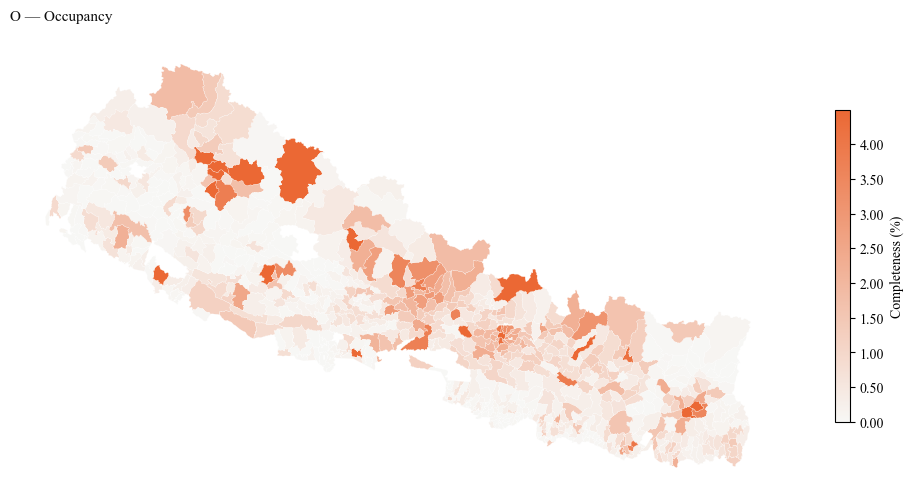

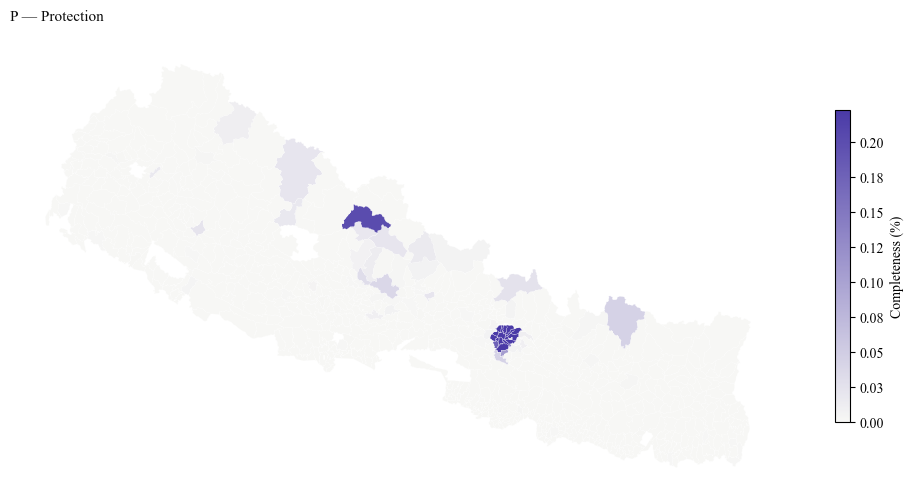

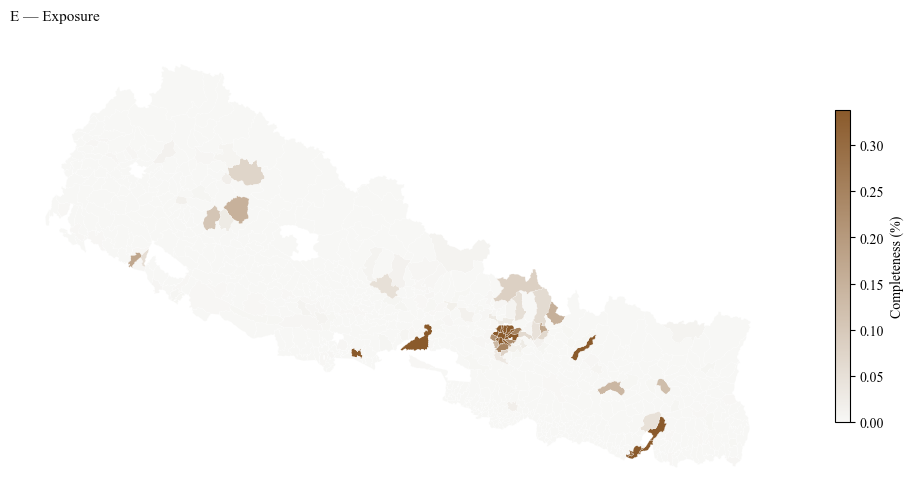

In [ ]:
## Map of completeness per municipality

from matplotlib.colors import LinearSegmentedColormap

# Single-hue colour ramp per category: near-white -> category colour (as in all other figures)
CAT_CMAPS = {cat: LinearSegmentedColormap.from_list(f"cmap_{cat}", ["#f7f7f5", color])
             for cat, color in CAT_COLORS.items()}


def plot_completeness_map(ax, cat):
    column = f"compl_{cat}_pct"
    # Scale from the percentiles: single outliers would otherwise dominate the colour scale.
    vmin, vmax = np.nanpercentile(muni[column], [2, 98])
    muni.plot(column=column, ax=ax, cmap=CAT_CMAPS[cat], vmin=vmin, vmax=vmax,
              edgecolor="white", linewidth=0.15, legend=True,
              legend_kwds={"shrink": 0.6, "label": "Completeness (%)", "format": "%.2f"},
              # hatched instead of grey, so it cannot be confused with the light end of the ramp
              missing_kwds={"color": "white", "edgecolor": MUTED, "hatch": "////", "linewidth": 0.15,
                            "label": "no buildings"})
    ax.set_title(f"{cat} — {CATEGORIES[cat]['name']}",
                 loc="left", fontsize=11, color=INK)
    ax.axis("off")


# All four categories together
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, cat in zip(axes.flat, CATEGORIES):
    plot_completeness_map(ax, cat)
fig.suptitle("COPE completeness per municipality", x=0.01, ha="left", fontsize=14, color=INK)
fig.tight_layout()
plt.show()

# Each category on its own
for cat in CATEGORIES:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    plot_completeness_map(ax, cat)
    fig.tight_layout()
    plt.show()

### 7.1 Spatial Autocorrelation: Moran's I

Global Moran's I of the attribute completeness per municipality (`compl_*_pct`), each category separately, across all municipalities of Nepal without aggregation. Neighbourhood: queen (municipalities whose borders touch), row-standardised weights. Test under randomisation, one-sided (I > E[I]), as `moran.test` in R/spdep. Municipalities without buildings (no completeness) are left out, also as neighbours.

In [ ]:
import shapely
from scipy.stats import norm

# Queen contiguity: two municipalities are neighbours if their borders touch (edge or corner)
muni_geoms = muni.geometry.to_numpy()
pair_i, pair_j = shapely.STRtree(muni_geoms).query(muni_geoms, predicate="intersects")
neighbours = np.zeros((len(muni), len(muni)))
neighbours[pair_i, pair_j] = 1
np.fill_diagonal(neighbours, 0)


def moran_test(values):
    # Global Moran's I, row-standardised weights, test under randomisation
    # (as moran.test in R/spdep, one-sided: I > E[I]).
    # Municipalities without a value (NaN) and municipalities without a neighbour with a value are left out.
    x = np.asarray(values, dtype=float)
    used = ~np.isnan(x)
    w = neighbours[np.ix_(used, used)]
    has_neighbour = w.sum(axis=1) > 0
    w = w[np.ix_(has_neighbour, has_neighbour)]
    w = w / w.sum(axis=1, keepdims=True)
    z = x[used][has_neighbour]
    z = z - z.mean()
    n = len(z)

    s0 = w.sum()
    s1 = 0.5 * ((w + w.T) ** 2).sum()
    s2 = ((w.sum(axis=1) + w.sum(axis=0)) ** 2).sum()
    i_obs = n / s0 * (z @ w @ z) / (z @ z)
    e_i = -1 / (n - 1)
    k = n * (z ** 4).sum() / (z @ z) ** 2
    var_i = (n * ((n ** 2 - 3 * n + 3) * s1 - n * s2 + 3 * s0 ** 2)
             - k * (n * (n - 1) * s1 - 2 * n * s2 + 6 * s0 ** 2)) \
        / ((n - 1) * (n - 2) * (n - 3) * s0 ** 2) - e_i ** 2
    std_deviate = (i_obs - e_i) / np.sqrt(var_i)
    return {"n": n, "moran_i": i_obs, "std_deviate": std_deviate, "p_value": norm.sf(std_deviate)}


moran = pd.DataFrame({f"{cat} ({info['name']})": moran_test(muni[f"compl_{cat}_pct"])
                      for cat, info in CATEGORIES.items()}).T
moran.index.name = "category"
moran["n"] = moran["n"].astype(int)
moran.style.format({"moran_i": "{:.4f}", "std_deviate": "{:.4f}", "p_value": "{:.3g}"})

,n,moran_i,std_deviate,p_value
category,,,,
C (Construction),750,0.2502,12.6948,3.16e-37
O (Occupancy),750,0.2738,12.4034,1.25e-35
P (Protection),750,0.7631,35.7384,5.02e-280
E (Exposure),750,0.0646,4.1941,1.37e-05


## 8. Gini Coefficient: How Unequally Are the Attributes Distributed?

how unequally are the COPE points of a category distributed across Nepal's municipalities?

**Computation:** The municipalities are sorted by points per building. We then compare which share of the buildings holds which share of the points (Lorenz curve). Each municipality is weighted by its number of buildings, so large municipalities count more.

- **Gini = 0:** every building in Nepal has the same number of attributes on average, regardless of the municipality.
- **Gini close to 1:** almost all attributes are concentrated in a few municipalities.

                   gini  completeness_pct  municipalities_with_data
category                                                           
C (Construction)  0.939             0.244                       358
O (Occupancy)     0.646             0.817                       708
P (Protection)    0.955             0.032                       100
E (Exposure)      0.949             0.121                       165


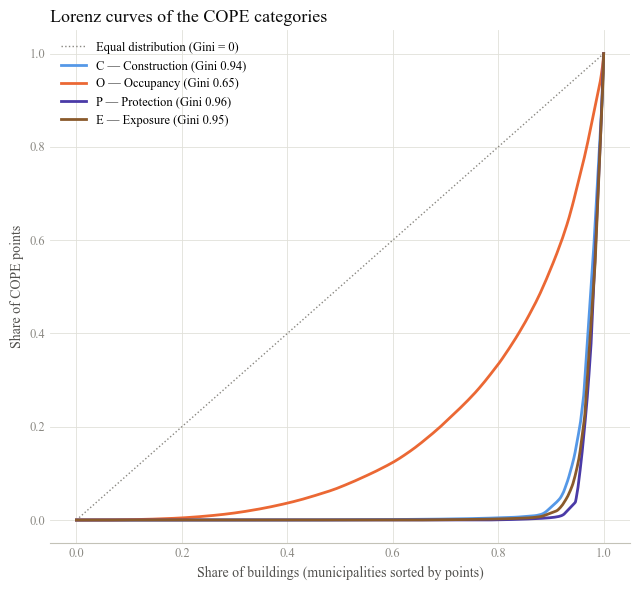

In [14]:
def lorenz_curve(values, weights):
    """Lorenz curve of the points per building across municipalities, weighted by number of buildings."""
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    keep = np.isfinite(values) & (weights > 0)
    order = np.argsort(values[keep])
    v, w = values[keep][order], weights[keep][order]
    cum_buildings = np.concatenate([[0], np.cumsum(w) / w.sum()])
    cum_points = np.concatenate([[0], np.cumsum(v * w) / (v * w).sum()])
    return cum_buildings, cum_points


def gini(values, weights):
    """Gini of the points per building across municipalities (area between Lorenz curve and diagonal)."""
    cum_buildings, cum_points = lorenz_curve(values, weights)
    return 1 - 2 * np.trapezoid(cum_points, cum_buildings)


gini_rows = []
for cat, info in CATEGORIES.items():
    gini_rows.append({
        "category": f"{cat} ({info['name']})",
        "gini": gini(muni[f"mean_{cat}"], muni["n_buildings"]),
        "completeness_pct": stats_cat.loc[f"{cat} ({info['name']})", "completeness_pct"],
        "municipalities_with_data": int((muni[f"with_{cat}"] > 0).sum()),
    })

gini_tab = pd.DataFrame(gini_rows).set_index("category")
print(gini_tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1, label="Equal distribution (Gini = 0)")
for cat, info in CATEGORIES.items():
    x, y = lorenz_curve(muni[f"mean_{cat}"], muni["n_buildings"])
    name = f"{cat} ({info['name']})"
    ax.plot(x, y, color=CAT_COLORS[cat], lw=2,
            label=f"{cat} — {info['name']} (Gini {gini_tab.loc[name, 'gini']:.2f})")
ax.set_xlabel("Share of buildings (municipalities sorted by points)", color=INK_SECONDARY, fontsize=10)
ax.set_ylabel("Share of COPE points", color=INK_SECONDARY, fontsize=10)
ax.set_title("Lorenz curves of the COPE categories", loc="left", fontsize=13, color=INK)
ax.legend(frameon=False, fontsize=9, loc="upper left")
style_axes(ax)
ax.grid(axis="y", color=GRID, lw=0.6)
fig.tight_layout()
plt.show()

## 9. Group Comparison (RQ3)

The same groupings as in `hospital_osm_coverage` and `school_osm_coverage`: province, municipality type and hazard zone of the district. The **building category** (9.2) is added as a fourth grouping.

Reported per group and category:

- `mean_*`: points per building (sum of points / sum of buildings, so large municipalities count accordingly more)
- `compl_*_pct`: attribute completeness, i.e. points per building relative to the maximum attainable points of the category. This is the number that makes C, O, P and E comparable.

### 9.1 Province, Municipality Type and Hazard Zone

===== province =====
                            n_municipalities  n_buildings  mean_C  compl_C_pct  mean_O  compl_O_pct  mean_P  compl_P_pct  mean_E  compl_E_pct
province                                                                                                                                     
Bagmati                                  119      1654998   0.115        1.146   0.072        1.810   0.009        0.153   0.021        0.537
Gandaki                                   85       836264   0.008        0.080   0.045        1.129   0.000        0.008   0.000        0.010
Koshi                                    137      1669009   0.002        0.023   0.025        0.634   0.000        0.000   0.001        0.021
Karnali                                   79       494980   0.001        0.005   0.024        0.593   0.000        0.001   0.000        0.005
Madhesh                                  136      1462126   0.000        0.005   0.012        0.292   0.000        0.000   0.00

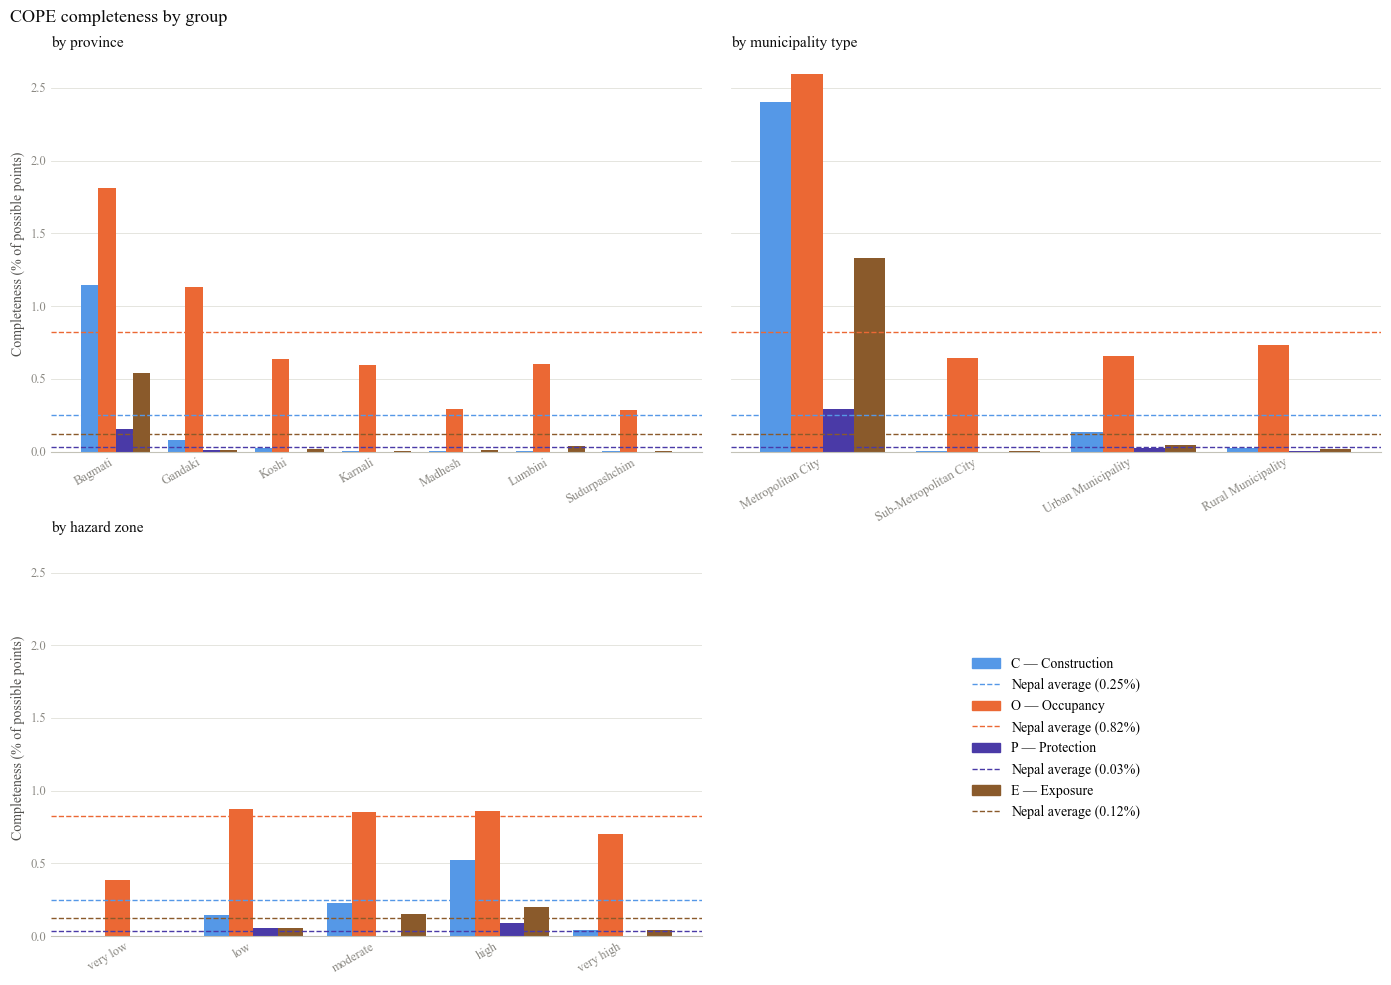

In [ ]:
def group_stats(df):
    row = {"n_municipalities": len(df), "n_buildings": int(df["n_buildings"].sum())}
    for cat in CATEGORIES:
        points = df[f"points_{cat}"].sum()
        row[f"mean_{cat}"] = points / row["n_buildings"] if row["n_buildings"] else np.nan
        row[f"compl_{cat}_pct"] = completeness(row[f"mean_{cat}"], cat)
    return pd.Series(row)


def group_table(by, order=None):
    out = pd.DataFrame({group: group_stats(g) for group, g in muni.groupby(by)}).T
    out = out.reindex(order) if order else out.sort_values("mean_C", ascending=False)
    out.loc["Nepal (all municipalities)"] = group_stats(muni)
    out[["n_municipalities", "n_buildings"]] = out[["n_municipalities", "n_buildings"]].astype(int)
    out.index.name = by
    return out


TYPE_ORDER = ["Metropolitan City", "Sub-Metropolitan City", "Urban Municipality", "Rural Municipality"]
groupings = [("province", group_table("province")),
             ("municipality type", group_table("municipality_type", TYPE_ORDER)),
             ("hazard zone", group_table("hazard_zone", HAZARD_ZONES))]

for title, table in groupings:
    print(f"===== {title} =====")
    print(table.round(3).to_string())
    print()

NATIONAL = "Nepal (all municipalities)"
national = groupings[0][1].loc[NATIONAL]


fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for ax, (title, table) in zip(axes.flat, groupings):
    groups = table.drop(index=NATIONAL)
    x = np.arange(len(groups))
    width = 0.2
    for k, cat in enumerate(CATEGORIES):
        ax.bar(x + (k - 1.5) * width, groups[f"compl_{cat}_pct"], width=width, color=CAT_COLORS[cat])
        # national average of the category as a dashed line
        ax.axhline(national[f"compl_{cat}_pct"], color=CAT_COLORS[cat], ls="--", lw=1)
    ax.set_xticks(x, groups.index, rotation=30, ha="right", fontsize=9, color=INK)
    ax.set_title(f"by {title}", loc="left", fontsize=11, color=INK)
    style_axes(ax, x_grid=False)
    ax.grid(axis="y", color=GRID, lw=0.6)
for ax in axes[:, 0]:
    ax.set_ylabel("Completeness (% of possible points)", color=INK_SECONDARY, fontsize=10)

# Legend in the free panel: per category the bar, then the dashed line with the national value
handles, labels = [], []
for cat in CATEGORIES:
    handles += [plt.Rectangle((0, 0), 1, 1, color=CAT_COLORS[cat]),
                plt.Line2D([], [], color=CAT_COLORS[cat], ls="--", lw=1)]
    labels += [f"{cat} — {CATEGORIES[cat]['name']}",
               f"Nepal average ({national[f'compl_{cat}_pct']:.2f}%)"]
legend_ax = axes[1, 1]
legend_ax.axis("off")
legend_ax.legend(handles, labels, loc="center", frameon=False, fontsize=10)
fig.suptitle("COPE completeness by group", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()

#### Kruskal-Wallis test: do the groups differ?

Kruskal-Wallis test of the attribute completeness per municipality (`compl_*_pct`) for each grouping and category, as `kruskal.test` in R. It tests whether completeness tends to be higher or lower in at least one group than in the others. Municipalities without buildings are left out (`df` = number of groups − 1).

In [16]:
from scipy.stats import kruskal


def kruskal_test(values, groups):
    # Kruskal-Wallis test (as kruskal.test in R). Municipalities without a value (NaN) are left out,
    # as are groups without a single value.
    samples = [v.dropna().to_numpy() for _, v in values.groupby(groups)]
    samples = [s for s in samples if len(s) > 0]
    h, p = kruskal(*samples)
    return {"n": sum(len(s) for s in samples), "chi_squared": h, "df": len(samples) - 1, "p_value": p}


rows = []
for grouping in ["province", "municipality_type", "hazard_zone"]:
    for cat, info in CATEGORIES.items():
        rows.append({"grouping": grouping, "category": f"{cat} ({info['name']})",
                     **kruskal_test(muni[f"compl_{cat}_pct"], muni[grouping])})

kruskal_wallis = pd.DataFrame(rows)
kruskal_wallis.style.hide(axis="index").format({"chi_squared": "{:.4f}", "p_value": "{:.3g}"})

grouping,category,n,chi_squared,df,p_value
province,C (Construction),750,117.1757,6,6.38e-23
province,O (Occupancy),750,187.5904,6,8.28e-38
province,P (Protection),750,76.1583,6,2.22e-14
province,E (Exposure),750,101.4019,6,1.28e-19
municipality_type,C (Construction),750,38.9027,3,1.82e-08
municipality_type,O (Occupancy),750,6.9138,3,0.0747
municipality_type,P (Protection),750,65.8726,3,3.26e-14
municipality_type,E (Exposure),750,55.9113,3,4.39e-12
hazard_zone,C (Construction),750,15.0284,4,0.00464
hazard_zone,O (Occupancy),750,34.8353,4,5.02e-07


### 9.2 Building Category

The category of a building comes from `building` **or** `amenity` in `buildings_points`. Both fields are merged.

- Buildings with `building = 'yes'` and no `amenity` carry no information about their use. They form a category of their own, **`unspecified`**, which serves as the baseline for the comparison. If such a building has an `amenity`, it is counted in that amenity category instead.
- If a building carries two different labels (e.g. `building = commercial`, `amenity = restaurant`), it appears in both categories. The sum over all categories is therefore larger than the number of buildings.
- Only categories with at least **10** buildings are considered.

77 building categories with at least 10 buildings (incl. 'unspecified'), 8,257,130 assignments in total

 building_category  n_buildings  compl_C_pct  compl_O_pct  compl_P_pct  compl_E_pct  compl_mean_pct
       educational           83        74.46        69.28        31.93        74.70           62.59
            health           14        64.29        57.14        21.43        75.00           54.46
         mixed_use          671        60.66        50.60        17.29        74.89           50.86
           college          628        67.48        75.36        22.37        18.75           45.99
            clinic          158        56.58        68.99        24.37        17.25           41.80
       health_post          156        50.32        64.74        21.05        14.10           37.55
            school         7089        51.89        64.59        19.19        14.47           37.53
      kindergarten          173        51.56        65.03        17.63        14.45           3

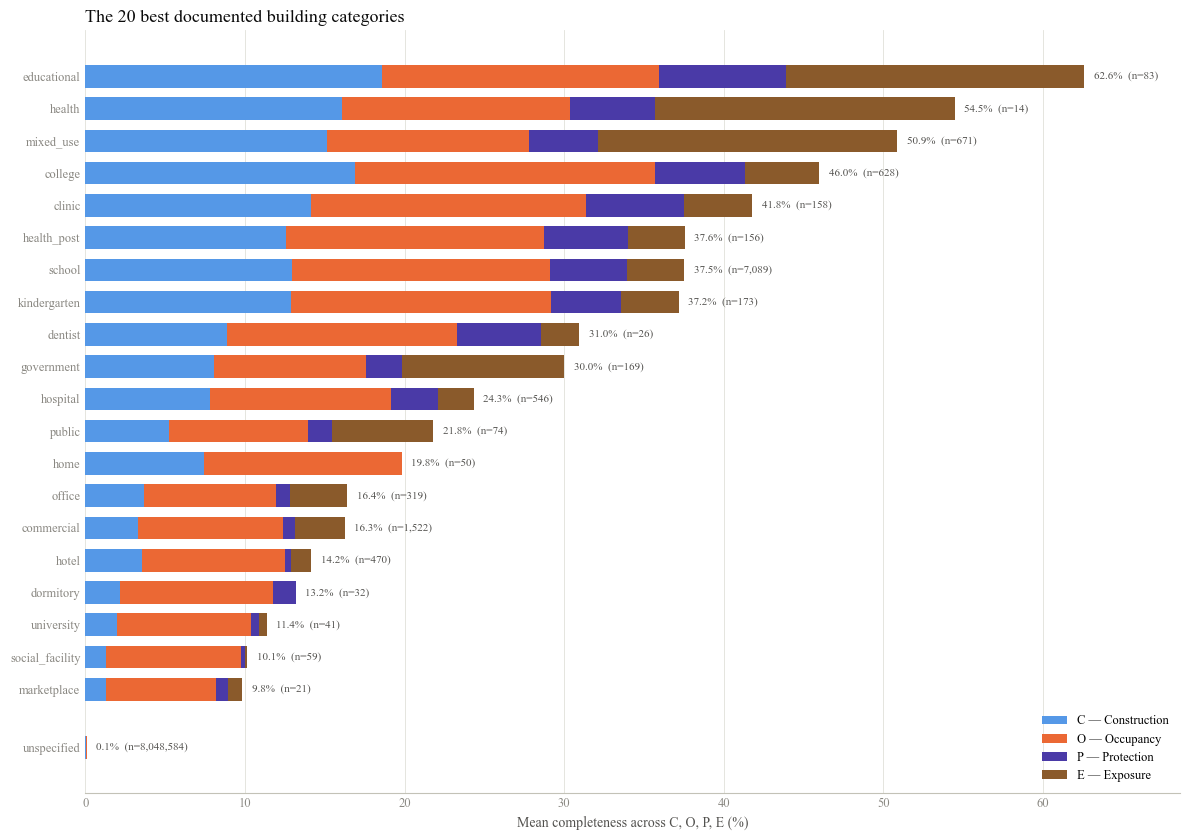

In [22]:
MIN_BUILDINGS = 10

cope_bldg = pd.read_sql(text(f"""
    WITH labels AS (
        SELECT osm_id, geom, building AS building_category FROM buildings_points
        WHERE building IS NOT NULL AND building <> 'yes'
        UNION                                        -- UNION (not ALL): duplicate labels per building are dropped
        SELECT osm_id, geom, amenity FROM buildings_points
        WHERE amenity IS NOT NULL AND amenity <> 'yes'
        UNION ALL                                    -- disjoint from the two sets above, no deduplication needed
        SELECT osm_id, geom, 'unspecified' FROM buildings_points
        WHERE building = 'yes' AND (amenity IS NULL OR amenity = 'yes')
    )
    SELECT l.building_category,
           COUNT(*) AS n_buildings,
           SUM(c."C") AS "points_C", SUM(c."O") AS "points_O",
           SUM(c."P") AS "points_P", SUM(c."E") AS "points_E"
    FROM labels l
    JOIN cope_scores c ON c.osm_id = l.osm_id AND c.geom = l.geom   -- osm_id alone is not unique (parts of multipolygon relations)
    GROUP BY l.building_category
    HAVING COUNT(*) >= {MIN_BUILDINGS}
"""), engine)

for cat in CATEGORIES:
    cope_bldg[f"mean_{cat}"] = cope_bldg[f"points_{cat}"] / cope_bldg["n_buildings"]
    cope_bldg[f"compl_{cat}_pct"] = completeness(cope_bldg[f"mean_{cat}"], cat)

cope_bldg["compl_mean_pct"] = cope_bldg[[f"compl_{c}_pct" for c in CATEGORIES]].mean(axis=1)
cope_bldg = cope_bldg.sort_values("compl_mean_pct", ascending=False).reset_index(drop=True)

cols = ["building_category", "n_buildings"] + [f"compl_{c}_pct" for c in CATEGORIES] + ["compl_mean_pct"]
print(f"{len(cope_bldg)} building categories with at least {MIN_BUILDINGS} buildings "
      f"(incl. 'unspecified'), {int(cope_bldg['n_buildings'].sum()):,} assignments in total\n")
print(cope_bldg[cols].round(2).to_string(index=False))

# the 20 best documented categories, with 'unspecified' as reference below a small gap
is_unspecified = cope_bldg["building_category"] == "unspecified"
top = pd.concat([cope_bldg[~is_unspecified].head(20), cope_bldg[is_unspecified]])
y = np.arange(len(top))[::-1].astype(float)
y[-1] -= 0.8

fig, ax = plt.subplots(figsize=(12, 8.5))
left = np.zeros(len(top))
for cat in CATEGORIES:
    part = (top[f"compl_{cat}_pct"] / len(CATEGORIES)).to_numpy()
    ax.barh(y, part, height=0.7, left=left, color=CAT_COLORS[cat], label=f"{cat} — {CATEGORIES[cat]['name']}")
    left += part
for yi, n, compl in zip(y, top["n_buildings"], top["compl_mean_pct"]):
    ax.text(compl + 0.6, yi, f"{compl:.1f}%  (n={n:,})", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_yticks(y, [c if c != "unspecified" else "unspecified" for c in top["building_category"]],
              fontsize=9, color=INK)
ax.set_xlabel("Mean completeness across C, O, P, E (%)", color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, top["compl_mean_pct"].max() + 6)   # room for the label next to the longest bar
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("The 20 best documented building categories", loc="left", fontsize=13, color=INK)
style_axes(ax)
fig.tight_layout()
plt.show()